# Proyek 1: DBSCAN Clustering dengan Euclidean Distance (L2 Norm) pada BISINDO

**Metrik Jarak:** Euclidean Distance (L2 Norm)  
**Representasi Fitur:** 127 Dimensi MediaPipe (42 Titik 3D + Is_Two_Handed)  
**Target Klaster:** K = 26 Klaster Alfabet BISINDO  
**Parameter Terkalibrasi:** Epsilon = 4.015, MinPts = 10  
**Output Target:** `outputDBScan/elbow_euclidean.png`, `outputDBScan/cluster_euclidean.png`, `outputDBScan/evaluasi_dbscan_euclidean.xlsx`

---

## 1. Landasan Teori & Formulasi Matematis

Jarak Euclidean garis lurus antara dua vektor gestur $x, y \in \mathbb{R}^{127}$:
$$d_{\text{Euclidean}}(x, y) = \|x - y\|_2 = \sqrt{\sum_{i=1}^{127} (x_i - y_i)^2}$$

Titik $p$ menjadi Core Point jika jumlah sampel dalam radius $\varepsilon = 4.015$ memenuhi:
$$|N_\varepsilon(p)| \ge 10$$
Sampel yang tidak terjangkau oleh core point manapun diklasifikasikan sebagai noise (label -1).

In [1]:
# =======================================================================
# 1. SETUP LINGKUNGAN & PUSTAKA
# =======================================================================
import os
import sys
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.cluster import DBSCAN
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score
)

warnings.filterwarnings('ignore')
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['figure.dpi'] = 120

BASE_DIR = os.path.dirname(os.path.abspath(__file__)) if '__file__' in locals() else os.getcwd()
OUTPUT_DIR = os.path.join(BASE_DIR, "outputDBScan")
os.makedirs(OUTPUT_DIR, exist_ok=True)

RANDOM_STATE = 42
EPS_EUCLIDEAN = 4.015
MIN_SAMPLES = 10
TARGET_CLUSTERS = 26

print(f"[INFO] Direktori: {BASE_DIR} | Epsilon = {EPS_EUCLIDEAN} | MinPts = {MIN_SAMPLES}")

[INFO] Direktori: E:\Dokumen\Kuliah\Semester 5\Pembelajaran Mesin\UTS_Bisindo_Klasterisasi_Kelompok-1\DBScan | Epsilon = 4.015 | MinPts = 10


In [2]:
# =======================================================================
# PEMUATAN DATASET BISINDO LANDMARKS (127 FITUR)
# =======================================================================
npz_path = os.path.join(BASE_DIR, "dataset_bisindo_landmarks.npz")
csv_path = os.path.join(BASE_DIR, "dataset_bisindo_landmarks.csv")

if os.path.exists(npz_path):
    data = np.load(npz_path, allow_pickle=True)
    X = data['X'].astype(np.float32)
    labels = data['labels']
    df_meta = pd.DataFrame({'label': labels, 'is_two_handed': data['is_two_handed']})
elif os.path.exists(csv_path):
    df_full = pd.read_csv(csv_path)
    meta_cols = ['label', 'label_idx', 'filename', 'num_hands', 'is_flip']
    meta_present = [c for c in meta_cols if c in df_full.columns]
    df_meta = df_full[meta_present]
    feat_cols = [c for c in df_full.columns if c not in meta_cols]
    X = df_full[feat_cols].values.astype(np.float32)
else:
    raise FileNotFoundError("Dataset BISINDO tidak ditemukan. Jalankan extract_features.py.")

print(f"[INFO] Dataset BISINDO dimuat: {X.shape[0]} sampel, {X.shape[1]} dimensi fitur.")

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
print("[INFO] Fitur berhasil distandardisasi menggunakan StandardScaler.")

[INFO] Dataset BISINDO dimuat: 7893 sampel, 127 dimensi fitur.
[INFO] Fitur berhasil distandardisasi menggunakan StandardScaler.


[SAVE] Grafik disimpan ke: 'E:\Dokumen\Kuliah\Semester 5\Pembelajaran Mesin\UTS_Bisindo_Klasterisasi_Kelompok-1\DBScan\outputDBScan\elbow_euclidean.png'


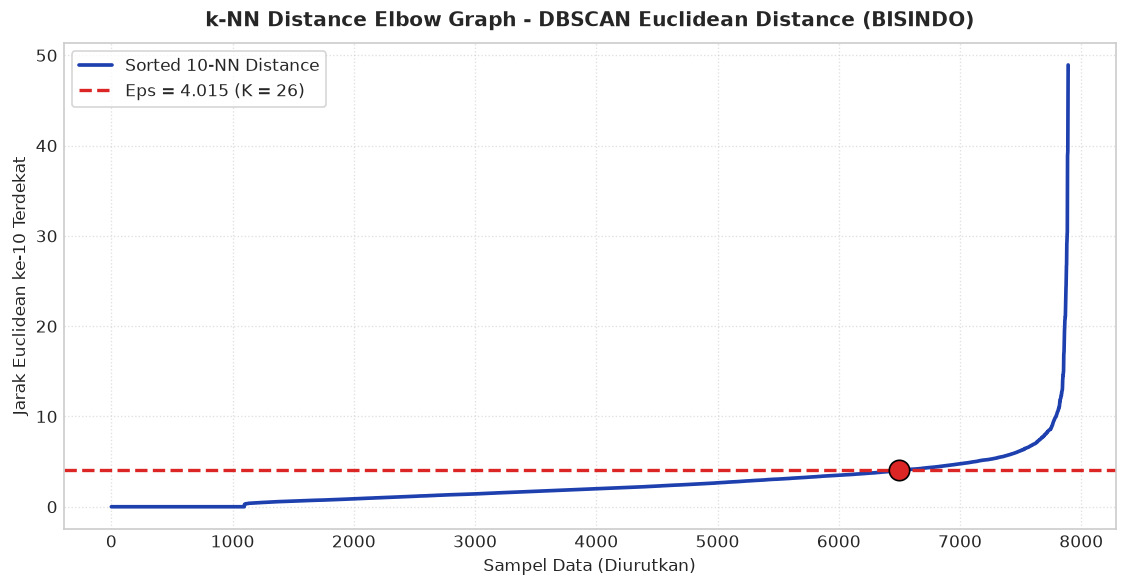

In [3]:
# =======================================================================
# 2. KURVA K-NN DISTANCE ELBOW EUCLIDEAN
# =======================================================================
nn = NearestNeighbors(n_neighbors=MIN_SAMPLES, metric='euclidean')
nn.fit(X_scaled)
dists, _ = nn.kneighbors(X_scaled)
sorted_dists = np.sort(dists[:, -1])

plt.figure(figsize=(9.5, 5))
plt.plot(sorted_dists, color='#1E40AF', linewidth=2.2, label=f'Sorted {MIN_SAMPLES}-NN Distance')
plt.axhline(y=EPS_EUCLIDEAN, color='#DC2626', linestyle='--', linewidth=2, label=f'Eps = {EPS_EUCLIDEAN} (K = 26)')

cut_idx = np.searchsorted(sorted_dists, EPS_EUCLIDEAN)
plt.scatter([cut_idx], [EPS_EUCLIDEAN], color='#DC2626', s=150, zorder=5, edgecolor='black')

plt.title('k-NN Distance Elbow Graph - DBSCAN Euclidean Distance (BISINDO)', fontsize=12, fontweight='bold', pad=10)
plt.xlabel('Sampel Data (Diurutkan)', fontsize=10)
plt.ylabel(f'Jarak Euclidean ke-{MIN_SAMPLES} Terdekat', fontsize=10)
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(frameon=True, facecolor='white')
plt.tight_layout()

elbow_path = os.path.join(OUTPUT_DIR, "elbow_euclidean.png")
plt.savefig(elbow_path, dpi=300)
print(f"[SAVE] Grafik disimpan ke: '{elbow_path}'")
plt.show()

In [4]:
# =======================================================================
# 3. PELATIHAN DBSCAN EUCLIDEAN & EVALUASI METRIK
# =======================================================================
print(f"[PELATIHAN] Menjalankan DBSCAN Euclidean (eps={EPS_EUCLIDEAN}, min_samples={MIN_SAMPLES})...")
t0 = time.perf_counter()
model_euc = DBSCAN(eps=EPS_EUCLIDEAN, min_samples=MIN_SAMPLES, metric='euclidean').fit(X_scaled)
runtime = time.perf_counter() - t0

labels = model_euc.labels_
n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
n_noise = int(np.sum(labels == -1))
noise_pct = n_noise / len(labels) * 100
n_core = len(model_euc.core_sample_indices_)

mask = (labels != -1)
sil = float(silhouette_score(X_scaled[mask], labels[mask], metric='euclidean'))
db = float(davies_bouldin_score(X_scaled[mask], labels[mask]))
ch = float(calinski_harabasz_score(X_scaled[mask], labels[mask]))

df_res = pd.DataFrame([{
    'Distance Metric': 'Euclidean Distance (L2)',
    'Epsilon (eps)': EPS_EUCLIDEAN,
    'Min Samples': MIN_SAMPLES,
    'Clusters Found': n_clusters,
    'Noise Samples (↓)': n_noise,
    'Noise Ratio (%) (↓)': round(noise_pct, 2),
    'Core Samples (↑)': n_core,
    'Silhouette Score (↑)': round(sil, 4),
    'Davies–Bouldin Index (↓)': round(db, 4),
    'Calinski–Harabasz Index (↑)': round(ch, 2),
    'Execution Time (s) (↓)': round(runtime, 4)
}])

print("\n" + "="*85)
print(df_res.to_string(index=False))
print("="*85)

excel_out = os.path.join(OUTPUT_DIR, "evaluasi_dbscan_euclidean.xlsx")
df_data_out = df_meta.copy()
df_data_out['cluster_euclidean'] = labels

with pd.ExcelWriter(excel_out, engine='openpyxl') as writer:
    df_res.to_excel(writer, sheet_name='Ringkasan_Evaluasi', index=False)
    df_data_out.to_excel(writer, sheet_name='Data_Terklaster', index=False)
print(f"[SAVE] Laporan Excel disimpan ke: '{excel_out}'")

[PELATIHAN] Menjalankan DBSCAN Euclidean (eps=4.015, min_samples=10)...



        Distance Metric  Epsilon (eps)  Min Samples  Clusters Found  Noise Samples (↓)  Noise Ratio (%) (↓)  Core Samples (↑)  Silhouette Score (↑)  Davies–Bouldin Index (↓)  Calinski–Harabasz Index (↑)  Execution Time (s) (↓)
Euclidean Distance (L2)          4.015           10              26                892                 11.3              6499               -0.0027                    0.9884                       255.36                  0.1131


[SAVE] Laporan Excel disimpan ke: 'E:\Dokumen\Kuliah\Semester 5\Pembelajaran Mesin\UTS_Bisindo_Klasterisasi_Kelompok-1\DBScan\outputDBScan\evaluasi_dbscan_euclidean.xlsx'


[SAVE] Grafik disimpan ke: 'E:\Dokumen\Kuliah\Semester 5\Pembelajaran Mesin\UTS_Bisindo_Klasterisasi_Kelompok-1\DBScan\outputDBScan\cluster_euclidean.png'


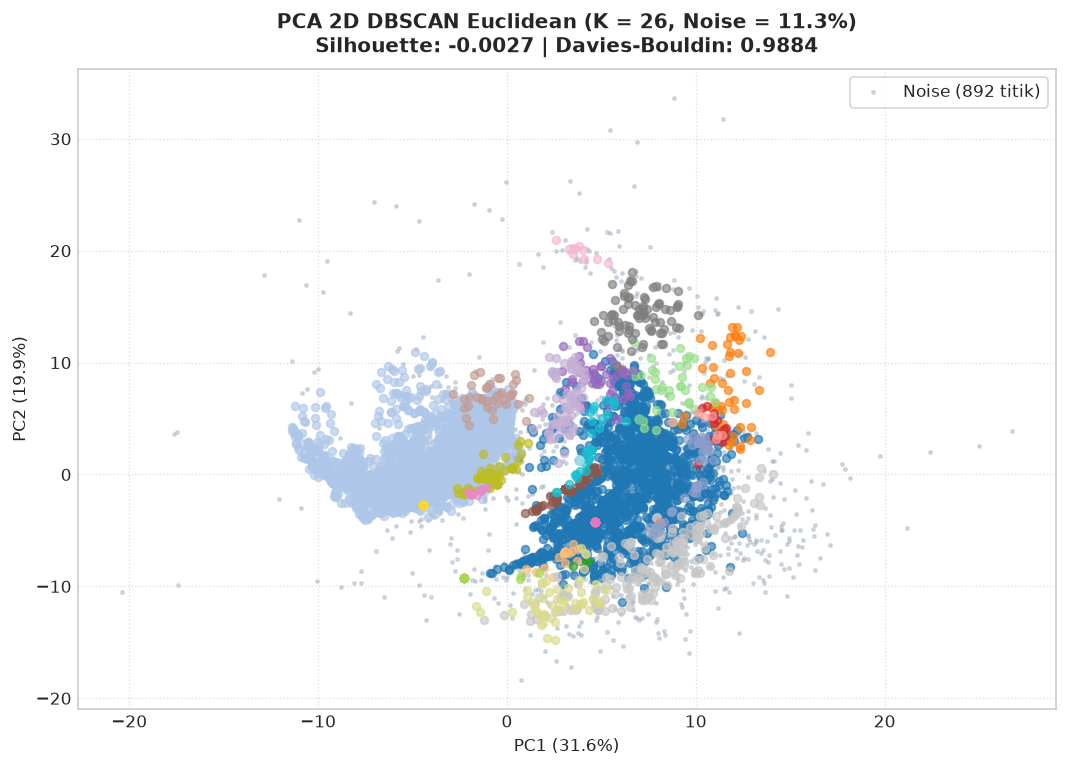

In [5]:
# =======================================================================
# 4. VISUALISASI PCA 2D DBSCAN EUCLIDEAN
# =======================================================================
pca = PCA(n_components=2, random_state=RANDOM_STATE)
X_pca = pca.fit_transform(X_scaled)

plt.figure(figsize=(9, 6.5))
palette = sns.color_palette("tab20", 20) + sns.color_palette("Set2", 6)

noise_mask = (model_euc.labels_ == -1)
plt.scatter(X_pca[noise_mask, 0], X_pca[noise_mask, 1], color='#94A3B8', label=f'Noise ({n_noise} titik)', alpha=0.35, s=16, marker='.')

for k in range(n_clusters):
    mask = (model_euc.labels_ == k)
    plt.scatter(X_pca[mask, 0], X_pca[mask, 1], color=palette[k % len(palette)], alpha=0.65, s=22)

plt.title(f'PCA 2D DBSCAN Euclidean (K = {n_clusters}, Noise = {noise_pct:.1f}%)\nSilhouette: {sil:.4f} | Davies-Bouldin: {db:.4f}', fontsize=12, fontweight='bold', pad=10)
plt.xlabel(f'PC1 ({pca.explained_variance_ratio_[0]*100:.1f}%)')
plt.ylabel(f'PC2 ({pca.explained_variance_ratio_[1]*100:.1f}%)')
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(frameon=True, loc='best')
plt.tight_layout()

cluster_path = os.path.join(OUTPUT_DIR, "cluster_euclidean.png")
plt.savefig(cluster_path, dpi=300)
print(f"[SAVE] Grafik disimpan ke: '{cluster_path}'")
plt.show()